# Cronus — Telecom Churn Exploratory Data Analysis

**analysis notebook | Canonical snapshot 2023-05-04 | 10,000 customer-provider relationships | 8,860 customers**

Cronus studies churn for telecom customers across providers. One row is one **customer-provider relationship**, not one unique customer. A customer can move between providers, hold several relationships over time, or return to a provider later. The analysis keeps that grain and reports two separate churn measures.

| Term | Definition |
|---|---|
| Relationship | One customer-provider row in the snapshot |
| History | All 10,000 relationships, including past relationships |
| Current | The latest relationship for each of the 8,860 customers |
| Relationship churn (all history) | 1,987 churned relationships / 10,000 = **19.87%** |
| Current customer churn (latest only) | 847 churned latest relationships / 8,860 = **9.56%** |

> **Do not mix the two rates.** 19.87% covers all history. 9.56% is the current customer churn rate. The 1,140 historical relationships are all churned by dataset construction, so they are not independent evidence of churn behavior.

This notebook answers four questions:

1. What does one row represent, and how does the snapshot encode customer history?
2. How does churn differ by provider, demographics, tenure, usage, geography, and registration cohort?
3. Which patterns are descriptive associations, and which are artifacts of the dataset construction?
4. What should modeling work model, and what must it exclude?

**Scope:** exploratory data analysis only. This notebook does not train a model, make causal claims, write to the database, or build a dashboard.

## Contents

1. [Title and executive summary](#1-title-and-executive-summary)
2. [Setup and reproducibility](#2-setup-and-reproducibility)
3. [Load and verify the snapshot](#3-load-and-verify-the-snapshot)
4. [Data quality and grain](#4-data-quality-and-grain)
5. [Dual churn semantics](#5-dual-churn-semantics)
6. [Univariate distributions](#6-univariate-distributions)
7. [Categorical churn drivers](#7-categorical-churn-drivers)
8. [Tenure and usage](#8-tenure-and-usage)
9. [Correlation and associations](#9-correlation-and-associations)
10. [Temporal and cohort view](#10-temporal-and-cohort-view)
11. [Segment interaction](#11-segment-interaction)
12. [Key findings and modeling handoff](#12-key-findings-and-modeling-handoff)
13. [Limitations and appendix](#13-limitations-and-appendix)

## 1. Title and executive summary

The snapshot contains 10,000 relationships for 8,860 customers. Of these, 1,020 customers hold more than one provider relationship, and 33 customer-provider pairs recur at a later date. These are valid observations, not duplicates.

The main findings are:

- **Usage intensity is the strongest descriptive signal.** Current churn falls from about 16–18% in the lowest calls, SMS, or data quartile to about 3% in the highest quartile.
- **Tenure matters.** Current churn is 12.1% for 0–90 days and 13.3% for 91–180 days, then falls to 6.6% after two years.
- **Provider matters.** BSNL has the highest current churn at 16.0%. Reliance Jio has the lowest at 5.9%. BSNL stays high across usage quartiles.
- **Older age bands and fewer dependents associate with higher current churn.** Gender shows no material difference.
- **Geography is weak and uncertain.** State differences are modest, and many states have small samples. Pincode changes in every multi-provider group, so it is not a reliable geographic key.
- **Recent registration cohorts show higher current churn.** This is consistent with their shorter tenure at the snapshot, not proof of a worsening trend.
- **modeling work must use the current relationship grain only.** Historical rows would leak the rule that every non-latest relationship is churned.

The rest of the notebook shows the evidence, the caveats, and the modeling handoff.

## 2. Setup and reproducibility

The notebook reads `Dataset/project_dataset.csv` through `cronus.validation.validate_csv`. This reuses the same normalisation and relationship derivation as the Streamlit ingestion path. The notebook needs no database connection and reads no environment secrets.

To run it from a fresh checkout:

```bash
uv sync --group notebook
uv run --group notebook jupyter lab Python/analysis.ipynb
```

The helper functions below only format results and compute Wilson confidence intervals. They do not change the data contract.

In [1]:
import hashlib
import sys
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, PercentFormatter

from cronus.validation import validate_csv

PALETTE = {
    "retained": "#2A9D8F",
    "churned": "#E76F51",
    "current": "#264653",
    "history": "#8D99AE",
    "accent": "#E9C46A",
    "ink": "#222222",
}
EXPECTED_SHA256 = "a1c3992fcb8da9523aa0f8074f87ce0c2247cac551e3a4fdee02c2690aa2f048"


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "Dataset" / "project_dataset.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate Dataset/project_dataset.csv")


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_PATH = PROJECT_ROOT / "Dataset" / "project_dataset.csv"

sns.set_theme(style="white", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "figure.figsize": (10, 5),
        "axes.grid": False,
        "grid.color": "none",
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "font.family": "DejaVu Sans",
    }
)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 30)

count_formatter = FuncFormatter(lambda value, _: f"{value:,.0f}")


def wilson_interval(successes: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - margin), min(1.0, centre + margin))


def churn_summary(frame: pd.DataFrame, by: str, min_n: int = 0) -> pd.DataFrame:
    grouped = frame.groupby(by, observed=True)
    out = grouped.agg(n=("churn", "size"), churned=("churn", "sum")).reset_index()
    out["rate_pct"] = 100 * out["churned"] / out["n"]
    intervals = [
        wilson_interval(int(churned), int(n))
        for churned, n in zip(out["churned"], out["n"], strict=False)
    ]
    out["ci_low_pct"] = [100 * low for low, _ in intervals]
    out["ci_high_pct"] = [100 * high for _, high in intervals]
    if min_n:
        out = out[out["n"] >= min_n].copy()
    return out

## 3. Load and verify the snapshot

The canonical file is byte-identical to the local source dataset. Its SHA-256 hash and its validation summary must match the data validation contract before any analysis starts. The cleaned frame contains the 14 source columns plus five derived fields: source row number, relationship sequence, relationship count, latest flag, and tenure.

In [2]:
file_sha256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
file_size = DATASET_PATH.stat().st_size

report, relationships = validate_csv(DATASET_PATH)

assert file_sha256 == EXPECTED_SHA256, "Dataset SHA-256 does not match the canonical file"
assert file_size == 842_073, "Dataset size does not match the canonical file"
assert report.error_count == 0, "The canonical file must validate without errors"
assert report.warning_count == 0, "The canonical file must validate without warnings"
assert report.row_count == 10_000, "Unexpected relationship count"
assert report.column_count == 14, "Unexpected source column count"
assert relationships.shape == (10_000, 19), "Unexpected cleaned frame shape"
assert report.unique_customers == 8_860, "Unexpected unique customer count"
assert report.multi_relationship_customers == 1_020, "Unexpected multi-provider count"
assert report.relationship_count_distribution == {"1": 7840, "2": 900, "3": 120}
assert report.reentry_pairs == 33, "Unexpected re-entry pair count"
assert report.as_of_date == date(2023, 5, 4), "Unexpected snapshot date"
assert report.date_min == date(2020, 1, 1), "Unexpected first registration date"
assert report.date_max == date(2023, 5, 4), "Unexpected last registration date"
assert report.relationship_churn_count == 1_987, "Unexpected relationship churn count"
assert report.relationship_churn_rate == 19.87, "Unexpected relationship churn rate"
assert report.historical_relationships == 1_140, "Unexpected historical count"
assert report.historical_churned == 1_140, "All historical relationships must be churned"
assert report.current_relationships == 8_860, "Unexpected current count"
assert report.current_churn_count == 847, "Unexpected current churn count"
assert report.current_churn_rate == 9.56, "Unexpected current churn rate"

validation_summary = pd.DataFrame(
    {
        "Field": [
            "Canonical file",
            "SHA-256",
            "File size",
            "Relationships",
            "Source columns",
            "Cleaned columns",
            "Unique customers",
            "Multi-provider customers",
            "Re-entry pairs",
            "Snapshot date",
            "Registration window",
            "Validation errors",
            "Validation warnings",
        ],
        "Value": [
            "Dataset/project_dataset.csv",
            f"{file_sha256[:16]}…",
            f"{file_size:,} bytes",
            f"{report.row_count:,}",
            f"{report.column_count}",
            f"{relationships.shape[1]}",
            f"{report.unique_customers:,}",
            f"{report.multi_relationship_customers:,}",
            f"{report.reentry_pairs}",
            f"{report.as_of_date:%Y-%m-%d}",
            f"{report.date_min:%Y-%m-%d} to {report.date_max:%Y-%m-%d}",
            f"{report.error_count}",
            f"{report.warning_count}",
        ],
    }
)
display(validation_summary.style.hide(axis="index"))

history = relationships.copy()
history["registration_date"] = pd.to_datetime(history["date_of_registration"])
history["relationship_type"] = np.where(
    history["is_latest_relationship"], "Current (latest)", "Historical"
)
current = history.loc[history["is_latest_relationship"]].copy()

assert len(current) == report.unique_customers
assert current["customer_id"].is_unique
assert current["is_latest_relationship"].all()
assert history.isna().sum().sum() == 0, "The cleaned frame must contain no missing values"
assert history.duplicated().sum() == 0, "The canonical file must contain no exact duplicate rows"
assert history["customer_id"].nunique() == report.unique_customers
assert (~history["is_latest_relationship"]).sum() == report.historical_relationships
assert history.loc[~history["is_latest_relationship"], "churn"].all()
assert int(history["churn"].sum()) == report.relationship_churn_count
assert int(current["churn"].sum()) == report.current_churn_count
assert round(100 * history["churn"].mean(), 2) == report.relationship_churn_rate
assert round(100 * current["churn"].mean(), 2) == report.current_churn_rate

display(
    history[
        [
            "customer_id",
            "telecom_partner",
            "gender",
            "age",
            "state",
            "date_of_registration",
            "churn",
            "relationship_seq",
            "relationship_count",
            "is_latest_relationship",
            "tenure_days",
        ]
    ].head(5)
)

Field,Value
Canonical file,Dataset/project_dataset.csv
SHA-256,a1c3992fcb8da952…
File size,"842,073 bytes"
Relationships,"10,000"
Source columns,14
Cleaned columns,19
Unique customers,"8,860"
Multi-provider customers,"1,020"
Re-entry pairs,33
Snapshot date,2023-05-04


,customer_id,telecom_partner,gender,age,state,date_of_registration,churn,relationship_seq,relationship_count,is_latest_relationship,tenure_days
0,1000-JBSYM,Reliance Jio,F,43,Kerala,2020-03-19,False,1,1,True,1141
1,1000-PNTJD,Reliance Jio,M,35,Tamil Nadu,2021-08-30,True,1,2,False,422
2,1000-PNTJD,Vodafone,M,36,Tamil Nadu,2022-10-26,False,2,2,True,190
3,1004-ERHIC,Airtel,M,62,Kerala,2020-02-10,True,1,2,False,761
4,1004-ERHIC,BSNL,M,64,Bihar,2022-03-12,True,2,2,True,418


A single customer timeline makes the grain concrete. The example below has three relationships and returns to a provider it used before. The rows are legitimate history, not duplicates.

In [3]:
multi3 = history[history["relationship_count"] == 3]
reentry_sizes = multi3.groupby(["customer_id", "telecom_partner"]).size()
reentry_ids = reentry_sizes[reentry_sizes > 1]

if len(reentry_ids):
    example_id = reentry_ids.index.get_level_values("customer_id")[0]
else:
    example_id = history.loc[history["relationship_count"] > 1, "customer_id"].iloc[0]

example = history[history["customer_id"] == example_id].sort_values("registration_date")
display(
    example[
        [
            "customer_id",
            "telecom_partner",
            "registration_date",
            "churn",
            "relationship_seq",
            "relationship_count",
            "is_latest_relationship",
            "tenure_days",
            "state",
            "pincode",
        ]
    ]
)

,customer_id,telecom_partner,registration_date,churn,relationship_seq,relationship_count,is_latest_relationship,tenure_days,state,pincode
338,1303-NXXUH,Airtel,2020-07-23,True,1,3,False,432,Karnataka,560760
339,1303-NXXUH,Vodafone,2021-09-28,True,2,3,False,522,Karnataka,560416
340,1303-NXXUH,Airtel,2023-03-04,False,3,3,True,61,Karnataka,560653


The example shows the intended semantics:

- `relationship_seq` orders the customer's relationships by registration date.
- Only the last relationship has `is_latest_relationship = True`.
- `tenure_days` uses the next registration date for historical rows and the snapshot date for the latest row.
- A repeated provider is a return relationship. It is not a duplicate.

## 4. Data quality and grain

The dataset has no missing values and no exact duplicate rows. The checks below focus on what the grain means and which fields are stable across a customer's relationships.

In [4]:
quality = pd.DataFrame(
    {
        "Check": [
            "Missing cells",
            "Exact duplicate rows",
            "Unique customer IDs",
            "Unique pincodes",
            "Unique states/UTs",
            "Unique cities",
            "Gender values",
            "Rows with data_used = 0",
            "Current rows with data_used = 0",
        ],
        "Result": [
            f"{int(history.isna().sum().sum()):,}",
            f"{int(history.duplicated().sum()):,}",
            f"{history['customer_id'].nunique():,}",
            f"{history['pincode'].nunique():,}",
            f"{history['state'].nunique():,}",
            f"{history['city'].nunique():,}",
            ", ".join(sorted(history["gender"].unique())),
            f"{int((history['data_used'] == 0).sum()):,}",
            f"{int((current['data_used'] == 0).sum()):,}",
        ],
    }
)
display(quality.style.hide(axis="index"))

multi = history[history["relationship_count"] > 1]
multi_groups = multi.groupby("customer_id")
stability = pd.DataFrame(
    {
        "Attribute": [
            "Gender",
            "Age",
            "State",
            "City",
            "Pincode",
            "Dependents",
            "Estimated salary",
        ],
        "Groups with changes": [
            int((multi_groups[column].nunique() > 1).sum())
            for column in [
                "gender",
                "age",
                "state",
                "city",
                "pincode",
                "num_dependents",
                "estimated_salary",
            ]
        ],
    }
)
stability["Share of multi-provider groups"] = (
    100 * stability["Groups with changes"] / multi["customer_id"].nunique()
)
display(
    stability.style.hide(axis="index").format(
        {"Groups with changes": "{:,}", "Share of multi-provider groups": "{:.1f}%"}
    )
)

Check,Result
Missing cells,0
Exact duplicate rows,0
Unique customer IDs,"8,860"
Unique pincodes,"8,851"
Unique states/UTs,32
Unique cities,81
Gender values,"F, M"
Rows with data_used = 0,43
Current rows with data_used = 0,40


Attribute,Groups with changes,Share of multi-provider groups
Gender,0,0.0%
Age,722,70.8%
State,157,15.4%
City,162,15.9%
Pincode,"1,020",100.0%
Dependents,231,22.6%
Estimated salary,"1,020",100.0%


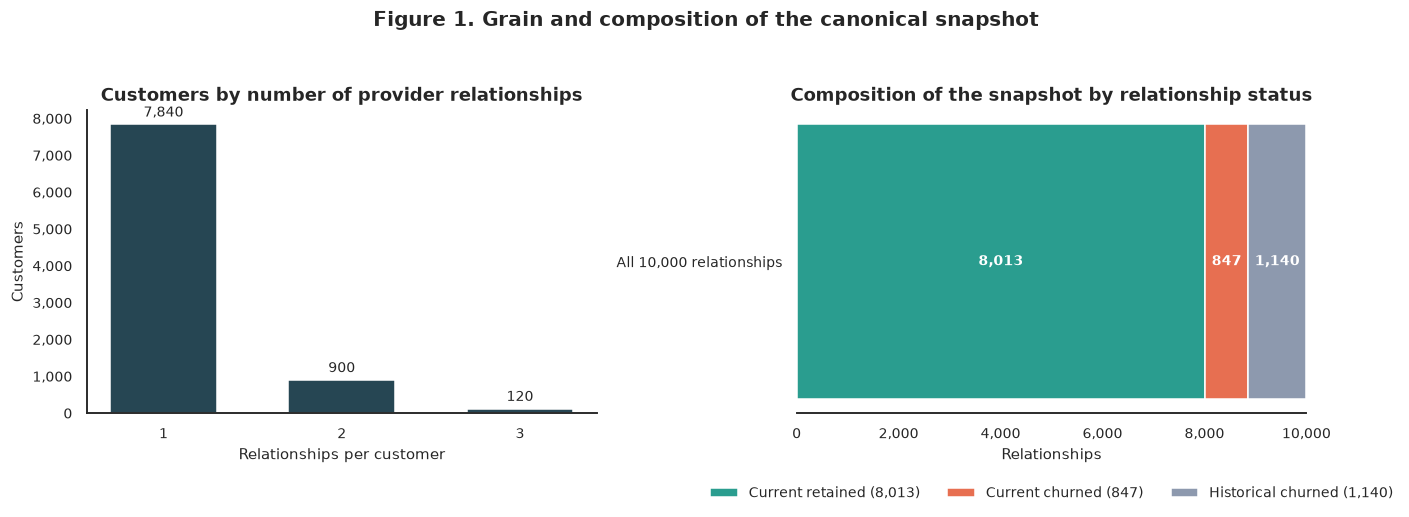

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

distribution = history.groupby("customer_id").size().value_counts().sort_index()
bars = axes[0].bar(
    distribution.index.astype(str),
    distribution.values,
    color=PALETTE["current"],
    width=0.6,
)
axes[0].bar_label(
    bars,
    labels=[f"{value:,}" for value in distribution.values],
    padding=3,
    fontsize=9,
)
axes[0].set_title("Customers by number of provider relationships")
axes[0].set_xlabel("Relationships per customer")
axes[0].set_ylabel("Customers")
axes[0].yaxis.set_major_formatter(count_formatter)
sns.despine(ax=axes[0])

segments = [
    (
        "Current retained",
        int(((history["relationship_type"] == "Current (latest)") & ~history["churn"]).sum()),
        PALETTE["retained"],
    ),
    (
        "Current churned",
        int(((history["relationship_type"] == "Current (latest)") & history["churn"]).sum()),
        PALETTE["churned"],
    ),
    (
        "Historical churned",
        int(((history["relationship_type"] == "Historical") & history["churn"]).sum()),
        PALETTE["history"],
    ),
]
assert sum(value for _, value, _ in segments) == len(history)
assert segments[1][1] == report.current_churn_count
assert segments[2][1] == report.historical_churned
left = 0
for label, value, color in segments:
    axes[1].barh(
        [0],
        [value],
        left=left,
        color=color,
        edgecolor="white",
        height=0.5,
        label=f"{label} ({value:,})",
    )
    axes[1].text(
        left + value / 2,
        0,
        f"{value:,}",
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )
    left += value
axes[1].set_yticks([0], ["All 10,000 relationships"])
axes[1].set_xlim(0, 10_000)
axes[1].set_xlabel("Relationships")
axes[1].xaxis.set_major_formatter(count_formatter)
axes[1].set_title("Composition of the snapshot by relationship status")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
sns.despine(ax=axes[1], left=True)
fig.suptitle(
    "Figure 1. Grain and composition of the canonical snapshot", fontsize=13, fontweight="bold"
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [6]:
pair_sizes = history.groupby(["customer_id", "telecom_partner"]).size()
reentry_pairs = pair_sizes[pair_sizes > 1]
pair_churn = history.groupby(["customer_id", "telecom_partner"])["churn"].agg(["size", "sum"])
reentry_churn = pair_churn.loc[reentry_pairs.index]
mixed_pairs = int(
    ((reentry_churn["sum"] > 0) & (reentry_churn["sum"] < reentry_churn["size"])).sum()
)
both_churned = int((reentry_churn["sum"] == reentry_churn["size"]).sum())

reentry_table = pd.DataFrame(
    {
        "Measure": [
            "Re-entry customer-provider pairs",
            "Pairs with one churned and one retained relationship",
            "Pairs with both relationships churned",
            "Rows that belong to re-entry pairs",
        ],
        "Count": [len(reentry_pairs), mixed_pairs, both_churned, int(len(reentry_pairs) * 2)],
    }
)
display(reentry_table.style.hide(axis="index").format({"Count": "{:,}"}))

Measure,Count
Re-entry customer-provider pairs,33
Pairs with one churned and one retained relationship,30
Pairs with both relationships churned,3
Rows that belong to re-entry pairs,66


The stability table explains several modeling choices:

- **Gender is stable.** It is a safe customer-level attribute.
- **Age changes in 722 groups.** This is plausible as time passes.
- **State and city change in a minority of groups.** Treat them as relationship-level context, not stable customer facts.
- **Pincode changes in all 1,020 groups.** A stable address cannot produce two or three pincodes for every customer. Treat pincode as synthetic noise and exclude it from modeling.
- **Estimated salary changes in all 1,020 groups.** Treat salary as a relationship-level attribute, not a stable customer attribute.
- **Dependents change in 231 groups.** The value is mostly stable, but it is not a fixed customer key.

Multi-provider rows and re-entry pairs are valid. The notebook never deduplicates them.

## 5. Dual churn semantics

The two churn measures answer different questions:

- **Relationship churn (all history)** counts every churned customer-provider relationship.
- **Current customer churn (latest only)** counts each customer once, using the latest relationship.

The denominators differ, so the rates must stay separate.

In [7]:
dual = pd.DataFrame(
    {
        "Measure": [
            "Relationship churn (all history)",
            "Current customer churn (latest relationship per customer)",
        ],
        "Churned": [report.relationship_churn_count, report.current_churn_count],
        "Denominator": [report.row_count, report.current_relationships],
    }
)
dual["Rate"] = 100 * dual["Churned"] / dual["Denominator"]
dual["95% CI"] = [
    f"{100 * low:.2f}% – {100 * high:.2f}%"
    for low, high in [
        wilson_interval(int(churned), int(n))
        for churned, n in zip(dual["Churned"], dual["Denominator"], strict=False)
    ]
]
display(
    dual.style.hide(axis="index").format(
        {"Churned": "{:,}", "Denominator": "{:,}", "Rate": "{:.2f}%"}
    )
)

Measure,Churned,Denominator,Rate,95% CI
Relationship churn (all history),"1,987","10,000",19.87%,19.10% – 20.66%
Current customer churn (latest relationship per customer),847,"8,860",9.56%,8.96% – 10.19%


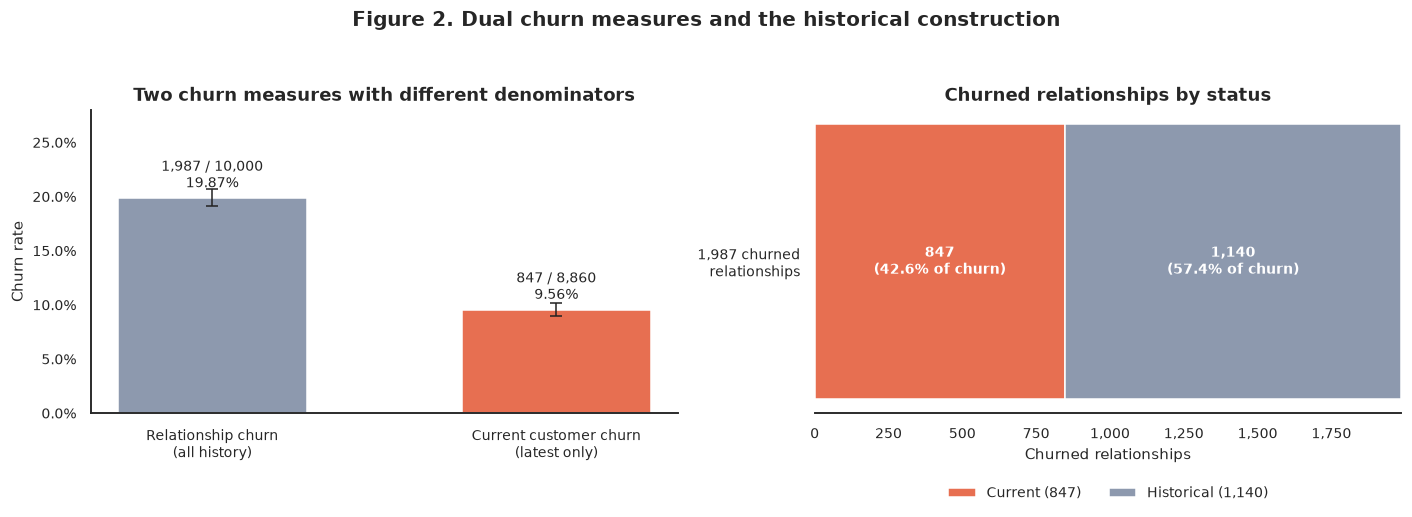

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels = [
    "Relationship churn\n(all history)",
    "Current customer churn\n(latest only)",
]
rates = [report.relationship_churn_rate, report.current_churn_rate]
counts = [report.relationship_churn_count, report.current_churn_count]
denominators = [report.row_count, report.current_relationships]
intervals = [
    wilson_interval(int(churned), int(n)) for churned, n in zip(counts, denominators, strict=False)
]
lower_error = [rate - 100 * low for rate, (low, _) in zip(rates, intervals, strict=False)]
upper_error = [100 * high - rate for rate, (_, high) in zip(rates, intervals, strict=False)]

bars = axes[0].bar(
    labels,
    rates,
    color=[PALETTE["history"], PALETTE["churned"]],
    width=0.55,
)
axes[0].errorbar(
    np.arange(len(rates)),
    rates,
    yerr=[lower_error, upper_error],
    fmt="none",
    ecolor=PALETTE["ink"],
    capsize=4,
    linewidth=1,
)
axes[0].bar_label(
    bars,
    labels=[
        f"{count:,} / {denom:,}\n{rate:.2f}%"
        for count, denom, rate in zip(counts, denominators, rates, strict=False)
    ],
    padding=4,
    fontsize=9,
)
axes[0].set_ylim(0, 28)
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[0].set_title("Two churn measures with different denominators")
sns.despine(ax=axes[0])

churned_parts = [
    ("Current", report.current_churn_count, PALETTE["churned"]),
    ("Historical", report.historical_churned, PALETTE["history"]),
]
left = 0
for label, value, color in churned_parts:
    axes[1].barh(
        [0],
        [value],
        left=left,
        color=color,
        edgecolor="white",
        height=0.45,
        label=f"{label} ({value:,})",
    )
    axes[1].text(
        left + value / 2,
        0,
        f"{value:,}\n({100 * value / report.relationship_churn_count:.1f}% of churn)",
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
    )
    left += value
axes[1].set_yticks([0], ["1,987 churned\nrelationships"])
axes[1].set_xlim(0, report.relationship_churn_count)
axes[1].set_xlabel("Churned relationships")
axes[1].xaxis.set_major_formatter(count_formatter)
axes[1].set_title("Churned relationships by status")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
sns.despine(ax=axes[1], left=True)

fig.suptitle(
    "Figure 2. Dual churn measures and the historical construction", fontsize=13, fontweight="bold"
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

> **The key caution.** The 19.87% rate covers all history. The 9.56% rate is the current customer churn rate. The 1,140 historical relationships are all churned because the dataset marks every non-latest relationship as churned. That rule is useful for history, but it would leak into a churn model. modeling work must use the current relationship grain only.

## 6. Univariate distributions

This section profiles the numeric fields on the current relationships. The history frame is shown for comparison, but the current frame is the relevant base for modeling work. Salary and data-used units are not documented, so the notebook labels them as source units.

In [9]:
numeric_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_days",
]
numeric_labels = {
    "age": "Age (years)",
    "num_dependents": "Dependents",
    "estimated_salary": "Estimated salary (source units)",
    "calls_made": "Calls made",
    "sms_sent": "SMS sent",
    "data_used": "Data used (source units)",
    "tenure_days": "Tenure (days)",
}


def summarize_numeric(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "Mean": frame[numeric_columns].mean(),
            "Median": frame[numeric_columns].median(),
            "P25": frame[numeric_columns].quantile(0.25),
            "P75": frame[numeric_columns].quantile(0.75),
            "Skew": frame[numeric_columns].skew(),
        }
    )


numeric_summary = pd.concat(
    {"History": summarize_numeric(history), "Current": summarize_numeric(current)},
    axis=1,
)
numeric_summary.index = [numeric_labels[name] for name in numeric_summary.index]
display(numeric_summary.style.format("{:,.1f}"))

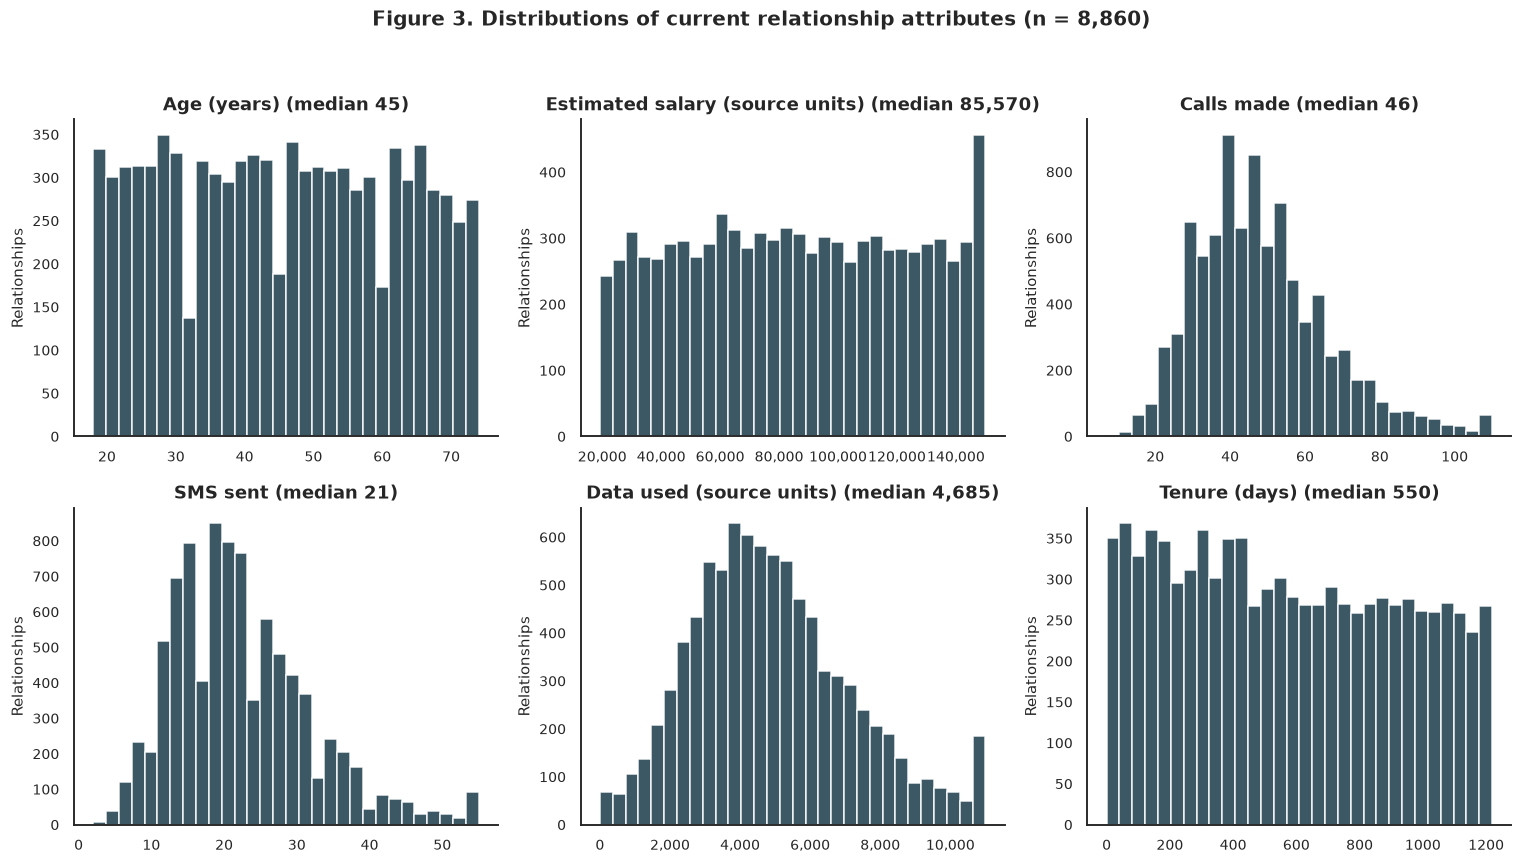

In [10]:
hist_columns = [
    "age",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_days",
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, column in zip(axes.flat, hist_columns, strict=False):
    values = current[column]
    ax.hist(values, bins=30, color=PALETTE["current"], edgecolor="white", alpha=0.9)
    median = values.median()
    ax.set_title(f"{numeric_labels[column]} (median {median:,.0f})")
    ax.set_ylabel("Relationships")
    ax.yaxis.set_major_formatter(count_formatter)
    if column in {"estimated_salary", "data_used"}:
        ax.xaxis.set_major_formatter(count_formatter)
    sns.despine(ax=ax)

fig.suptitle(
    "Figure 3. Distributions of current relationship attributes (n = 8,860)",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

The distributions are smooth and roughly symmetric, which is consistent with a synthetic snapshot. Age covers 18–74, dependents covers 0–4, and salary is close to uniform. Calls, SMS, and data have slight right tails. The notebook uses medians and quartiles for description, not normality assumptions.

The categorical base is small: four providers, two genders, 32 states/UTs, 81 cities, and 8,851 pincodes. City and pincode are too granular for stable segment estimates.

## 7. Categorical churn drivers

Provider is the clearest categorical split. The chart shows both grains so the construction artifact stays visible.

In [11]:
partner_history = churn_summary(history, "telecom_partner").rename(
    columns={
        "n": "history_n",
        "churned": "history_churned",
        "rate_pct": "history_rate_pct",
        "ci_low_pct": "history_ci_low_pct",
        "ci_high_pct": "history_ci_high_pct",
    }
)
partner_current = churn_summary(current, "telecom_partner").rename(
    columns={
        "n": "current_n",
        "churned": "current_churned",
        "rate_pct": "current_rate_pct",
        "ci_low_pct": "current_ci_low_pct",
        "ci_high_pct": "current_ci_high_pct",
    }
)
partner = partner_history.merge(partner_current, on="telecom_partner")
partner["current_lift"] = partner["current_rate_pct"] / report.current_churn_rate
partner = partner.sort_values("current_rate_pct", ascending=False).reset_index(drop=True)

partner_display = pd.DataFrame(
    {
        "Provider": partner["telecom_partner"],
        "Relationships": partner["history_n"],
        "Relationship churn": partner["history_churned"],
        "Relationship rate": partner["history_rate_pct"].map(lambda value: f"{value:.2f}%"),
        "Current relationships": partner["current_n"],
        "Current churn": partner["current_churned"],
        "Current rate": partner["current_rate_pct"].map(lambda value: f"{value:.2f}%"),
        "Current 95% CI": [
            f"{low:.2f}% – {high:.2f}%"
            for low, high in zip(
                partner["current_ci_low_pct"], partner["current_ci_high_pct"], strict=False
            )
        ],
        "Lift vs overall": partner["current_lift"].map(lambda value: f"{value:.2f}×"),
    }
)
display(partner_display.style.hide(axis="index"))

Provider,Relationships,Relationship churn,Relationship rate,Current relationships,Current churn,Current rate,Current 95% CI,Lift vs overall
BSNL,1853,455,24.55%,1664,266,15.99%,14.30% – 17.82%,1.67×
Airtel,2762,549,19.88%,2442,229,9.38%,8.28% – 10.60%,0.98×
Vodafone,2421,468,19.33%,2151,198,9.21%,8.05% – 10.50%,0.96×
Reliance Jio,2964,515,17.38%,2603,154,5.92%,5.07% – 6.89%,0.62×


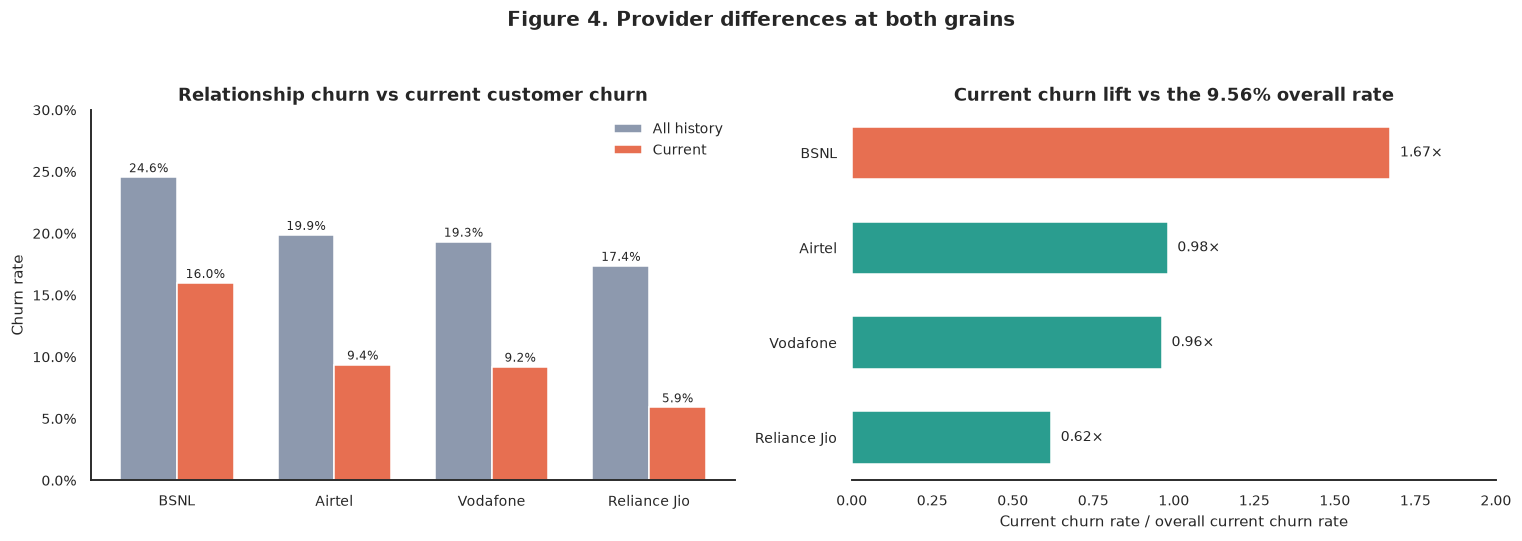

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(partner))
width = 0.36
history_bars = axes[0].bar(
    x - width / 2,
    partner["history_rate_pct"],
    width=width,
    color=PALETTE["history"],
    label="All history",
)
current_bars = axes[0].bar(
    x + width / 2,
    partner["current_rate_pct"],
    width=width,
    color=PALETTE["churned"],
    label="Current",
)
for index, (history_rate, current_rate) in enumerate(
    zip(partner["history_rate_pct"], partner["current_rate_pct"], strict=False)
):
    axes[0].text(
        index - width / 2, history_rate + 0.4, f"{history_rate:.1f}%", ha="center", fontsize=8
    )
    axes[0].text(
        index + width / 2, current_rate + 0.4, f"{current_rate:.1f}%", ha="center", fontsize=8
    )
axes[0].set_xticks(x, partner["telecom_partner"])
axes[0].set_ylim(0, 30)
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[0].set_title("Relationship churn vs current customer churn")
axes[0].legend(frameon=False)
sns.despine(ax=axes[0])

y = np.arange(len(partner))
lift_colors = [
    PALETTE["churned"] if value > 1 else PALETTE["retained"] for value in partner["current_lift"]
]
axes[1].barh(y, partner["current_lift"], color=lift_colors, height=0.55)
for index, value in enumerate(partner["current_lift"]):
    axes[1].text(value + 0.03, index, f"{value:.2f}×", va="center", fontsize=9)
axes[1].set_yticks(y, partner["telecom_partner"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 2.0)
axes[1].set_xlabel("Current churn rate / overall current churn rate")
axes[1].set_title("Current churn lift vs the 9.56% overall rate")
sns.despine(ax=axes[1], left=True)

fig.suptitle("Figure 4. Provider differences at both grains", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

BSNL has the highest current churn at 16.0% (266 of 1,664), which is 1.67 times the overall rate. Reliance Jio has the lowest at 5.9% (154 of 2,603), or 0.62 times the overall rate. Airtel and Vodafone sit near the overall level.

The history rates differ less, and the ordering is not the same. That is another reason to keep the current base separate. The history rate is not a behavioral benchmark.

Gender shows no material difference. The current rates are 9.51% for F and 9.59% for M, and the confidence intervals overlap. The notebook does not chart gender.

In [13]:
gender_current = churn_summary(current, "gender")
gender_display = pd.DataFrame(
    {
        "Gender": gender_current["gender"],
        "Current relationships": gender_current["n"],
        "Current churn": gender_current["churned"],
        "Current rate": gender_current["rate_pct"].map(lambda value: f"{value:.2f}%"),
        "Current 95% CI": [
            f"{low:.2f}% – {high:.2f}%"
            for low, high in zip(
                gender_current["ci_low_pct"], gender_current["ci_high_pct"], strict=False
            )
        ],
    }
)
display(gender_display.style.hide(axis="index"))

Gender,Current relationships,Current churn,Current rate,Current 95% CI
F,3616,344,9.51%,8.60% – 10.51%
M,5244,503,9.59%,8.82% – 10.42%


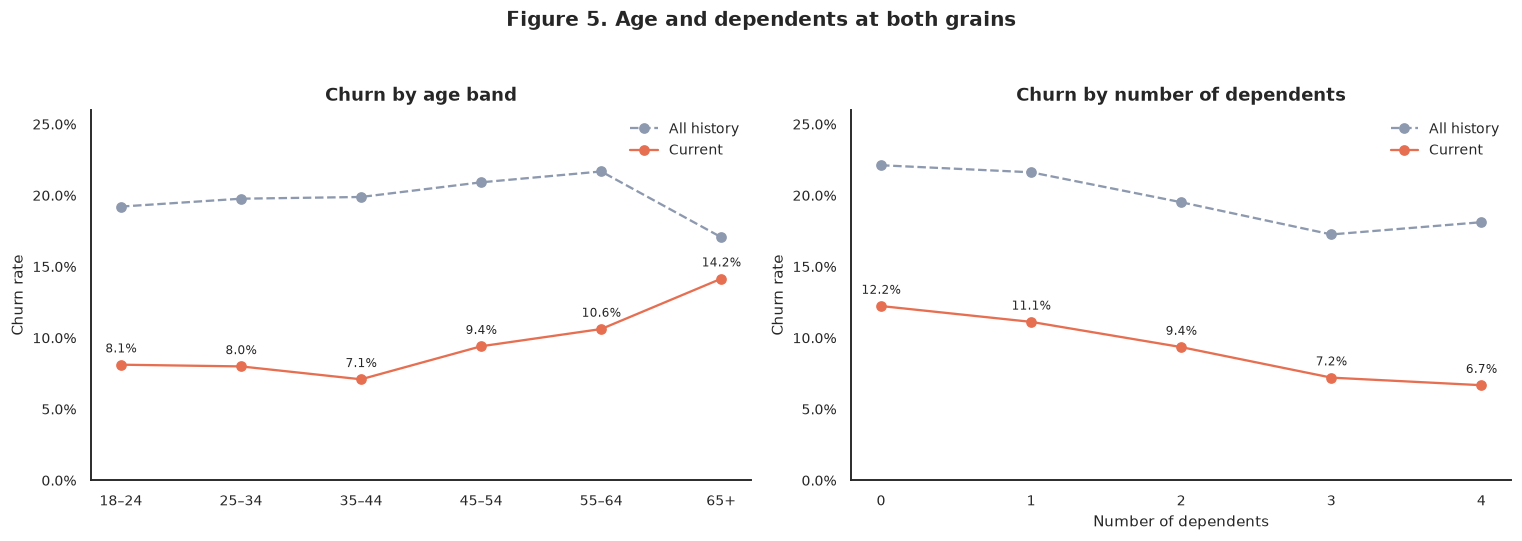

In [14]:
age_bins = [17, 24, 34, 44, 54, 64, 100]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
history["age_band"] = pd.cut(history["age"], bins=age_bins, labels=age_labels)
current["age_band"] = pd.cut(current["age"], bins=age_bins, labels=age_labels)

age_history = churn_summary(history, "age_band")
age_current = churn_summary(current, "age_band")
age_history_series = age_history.set_index("age_band")["rate_pct"].reindex(age_labels)
age_current_series = age_current.set_index("age_band")["rate_pct"].reindex(age_labels)

dependent_history = churn_summary(history, "num_dependents")
dependent_current = churn_summary(current, "num_dependents")
dependent_labels = [0, 1, 2, 3, 4]
dependent_history_series = dependent_history.set_index("num_dependents")["rate_pct"].reindex(
    dependent_labels
)
dependent_current_series = dependent_current.set_index("num_dependents")["rate_pct"].reindex(
    dependent_labels
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_age = np.arange(len(age_labels))
axes[0].plot(
    x_age,
    age_history_series.values,
    marker="o",
    color=PALETTE["history"],
    linestyle="--",
    label="All history",
)
axes[0].plot(
    x_age,
    age_current_series.values,
    marker="o",
    color=PALETTE["churned"],
    label="Current",
)
for index, value in enumerate(age_current_series.values):
    axes[0].annotate(
        f"{value:.1f}%",
        (index, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )
axes[0].set_xticks(x_age, age_labels)
axes[0].set_ylim(0, 26)
axes[0].set_ylabel("Churn rate")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[0].set_title("Churn by age band")
axes[0].legend(frameon=False)
sns.despine(ax=axes[0])

x_dep = np.arange(len(dependent_labels))
axes[1].plot(
    x_dep,
    dependent_history_series.values,
    marker="o",
    color=PALETTE["history"],
    linestyle="--",
    label="All history",
)
axes[1].plot(
    x_dep,
    dependent_current_series.values,
    marker="o",
    color=PALETTE["churned"],
    label="Current",
)
for index, value in enumerate(dependent_current_series.values):
    axes[1].annotate(
        f"{value:.1f}%",
        (index, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )
axes[1].set_xticks(x_dep, dependent_labels)
axes[1].set_ylim(0, 26)
axes[1].set_xlabel("Number of dependents")
axes[1].set_ylabel("Churn rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[1].set_title("Churn by number of dependents")
axes[1].legend(frameon=False)
sns.despine(ax=axes[1])

fig.suptitle("Figure 5. Age and dependents at both grains", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Current churn rises with age. It is 8.1% in the 18–24 band and 14.2% in the 65+ band. The history line is flatter, so the age pattern is strongest in the current base.

Current churn falls as the number of dependents rises. It is 12.2% with no dependents and 6.7% with four dependents. The history line follows the same direction, but the current line separates more clearly.

These are descriptive associations. The snapshot does not show why age or dependents relate to churn.

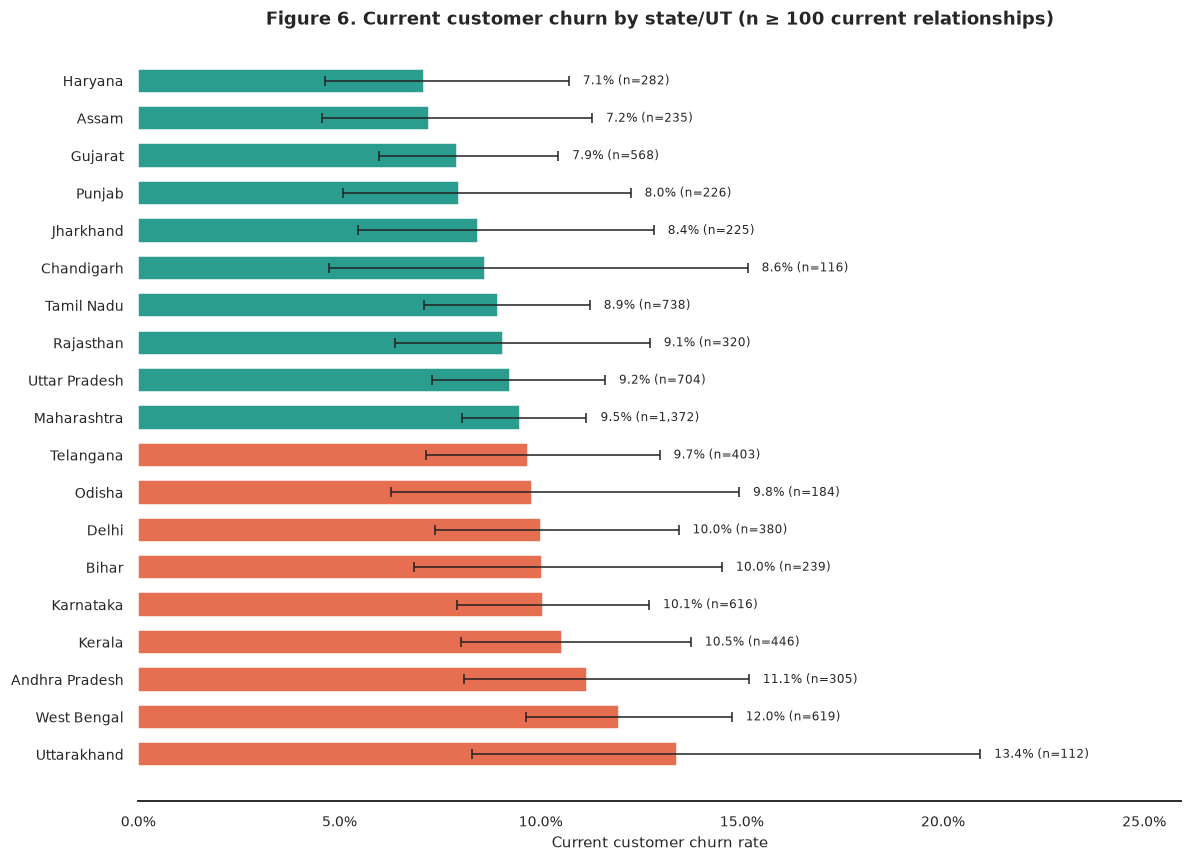

In [15]:
state_current = churn_summary(current, "state", min_n=100).sort_values("rate_pct")
y_state = np.arange(len(state_current))
state_colors = [
    PALETTE["churned"] if rate > report.current_churn_rate else PALETTE["retained"]
    for rate in state_current["rate_pct"]
]

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(y_state, state_current["rate_pct"], color=state_colors, height=0.65)
ax.errorbar(
    state_current["rate_pct"],
    y_state,
    xerr=[
        state_current["rate_pct"] - state_current["ci_low_pct"],
        state_current["ci_high_pct"] - state_current["rate_pct"],
    ],
    fmt="none",
    ecolor=PALETTE["ink"],
    capsize=3,
    linewidth=1,
)
for index, (rate, n, high) in enumerate(
    zip(
        state_current["rate_pct"],
        state_current["n"],
        state_current["ci_high_pct"],
        strict=True,
    )
):
    ax.text(max(rate, high) + 0.35, index, f"{rate:.1f}% (n={n:,})", va="center", fontsize=8)
ax.set_yticks(y_state, state_current["state"])
ax.invert_yaxis()
ax.set_xlim(0, state_current["ci_high_pct"].max() + 5)
ax.set_xlabel("Current customer churn rate")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_title("Figure 6. Current customer churn by state/UT (n ≥ 100 current relationships)")
sns.despine(ax=ax, left=True)
fig.tight_layout()
plt.show()

The state chart includes 19 states/UTs with at least 100 current relationships. The other 13 have 42–89 current rows and are omitted. Uttarakhand has the highest rate at 13.4% (n=112). West Bengal follows at 12.0% (n=619). Haryana has the lowest at 7.1% (n=282). The differences are modest, and several confidence intervals overlap. Use state as context, not as a causal explanation or a precise geographic key.

## 8. Tenure and usage

Tenure is the estimated days with a provider. For a historical relationship, the next registration date is the proxy switch date. For the latest relationship, the snapshot date ends observation. This is a proxy, not a recorded churn date.

Usage intensity is measured with calls, SMS, and data. All three are relationship-level counts. The units for data are not documented, so the chart labels them as source units.

In [16]:
tenure_bins = [-1, 90, 180, 365, 730, 10_000]
tenure_labels = ["0–90", "91–180", "181–365", "366–730", "731+"]
history["tenure_band"] = pd.cut(history["tenure_days"], bins=tenure_bins, labels=tenure_labels)
current["tenure_band"] = pd.cut(current["tenure_days"], bins=tenure_bins, labels=tenure_labels)

tenure_history = churn_summary(history, "tenure_band")
tenure_current = churn_summary(current, "tenure_band")

tenure_table = pd.DataFrame(
    {
        "Tenure band (days)": tenure_labels,
        "History n": tenure_history.set_index("tenure_band").reindex(tenure_labels)["n"].values,
        "History rate": tenure_history.set_index("tenure_band")
        .reindex(tenure_labels)["rate_pct"]
        .map(lambda value: f"{value:.2f}%")
        .values,
        "Current n": tenure_current.set_index("tenure_band").reindex(tenure_labels)["n"].values,
        "Current rate": tenure_current.set_index("tenure_band")
        .reindex(tenure_labels)["rate_pct"]
        .map(lambda value: f"{value:.2f}%")
        .values,
        "Current 95% CI": [
            f"{low:.2f}% – {high:.2f}%"
            for low, high in zip(
                tenure_current.set_index("tenure_band").reindex(tenure_labels)["ci_low_pct"],
                tenure_current.set_index("tenure_band").reindex(tenure_labels)["ci_high_pct"],
                strict=False,
            )
        ],
    }
)
display(tenure_table.style.hide(axis="index").format({"History n": "{:,}", "Current n": "{:,}"}))

Tenure band (days),History n,History rate,Current n,Current rate,Current 95% CI
0–90,792,12.12%,792,12.12%,10.03% – 14.58%
91–180,872,22.82%,776,13.27%,11.07% – 15.84%
181–365,"1,754",26.80%,"1,456",11.81%,10.25% – 13.57%
366–730,"3,156",24.37%,"2,652",9.99%,8.91% – 11.19%
731+,"3,426",13.22%,"3,184",6.63%,5.81% – 7.54%


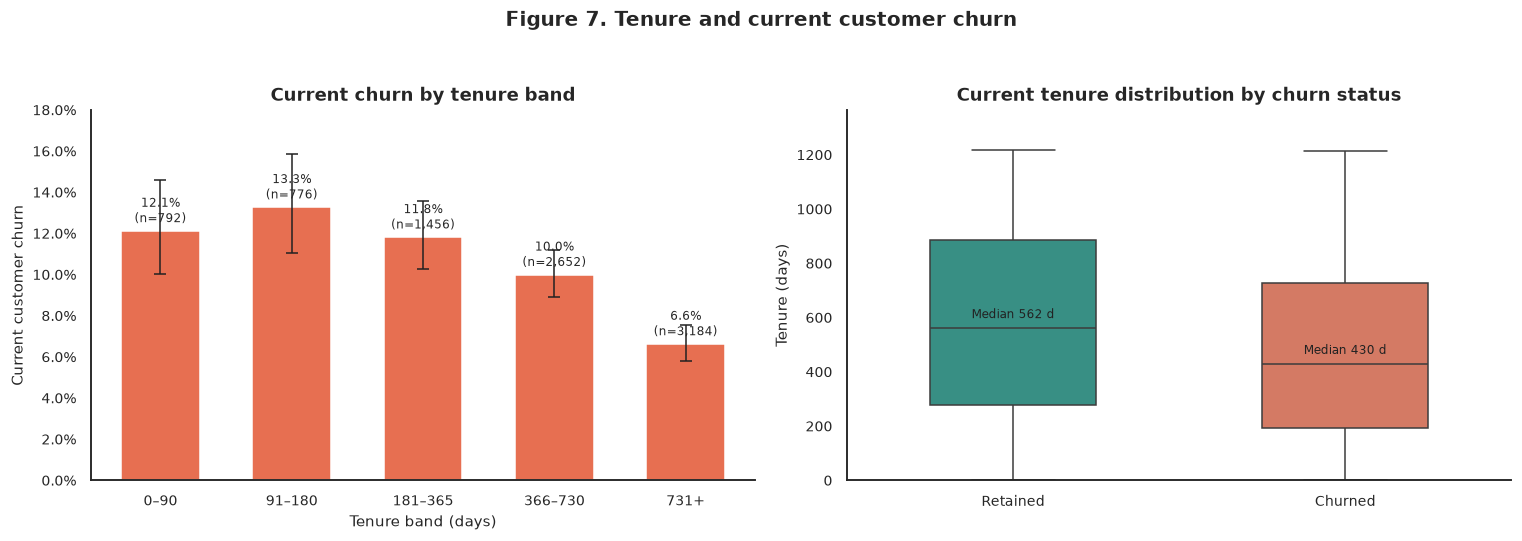

In [17]:
current_status = current.assign(status=np.where(current["churn"], "Churned", "Retained"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tenure_plot = tenure_current.set_index("tenure_band").reindex(tenure_labels)
bars = axes[0].bar(
    np.arange(len(tenure_labels)),
    tenure_plot["rate_pct"],
    color=PALETTE["churned"],
    width=0.6,
)
axes[0].errorbar(
    np.arange(len(tenure_labels)),
    tenure_plot["rate_pct"],
    yerr=[
        tenure_plot["rate_pct"] - tenure_plot["ci_low_pct"],
        tenure_plot["ci_high_pct"] - tenure_plot["rate_pct"],
    ],
    fmt="none",
    ecolor=PALETTE["ink"],
    capsize=4,
    linewidth=1,
)
axes[0].bar_label(
    bars,
    labels=[
        f"{rate:.1f}%\n(n={n:,})"
        for rate, n in zip(tenure_plot["rate_pct"], tenure_plot["n"], strict=False)
    ],
    padding=3,
    fontsize=8,
)
axes[0].set_xticks(np.arange(len(tenure_labels)), tenure_labels)
axes[0].set_ylim(0, 18)
axes[0].set_xlabel("Tenure band (days)")
axes[0].set_ylabel("Current customer churn")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[0].set_title("Current churn by tenure band")
sns.despine(ax=axes[0])

sns.boxplot(
    data=current_status,
    x="status",
    y="tenure_days",
    hue="status",
    palette={"Retained": PALETTE["retained"], "Churned": PALETTE["churned"]},
    legend=False,
    width=0.5,
    ax=axes[1],
)
for index, status in enumerate(["Retained", "Churned"]):
    median = current_status.loc[current_status["status"] == status, "tenure_days"].median()
    axes[1].text(
        index,
        median + 25,
        f"Median {median:,.0f} d",
        ha="center",
        va="bottom",
        fontsize=8,
        color=PALETTE["ink"],
    )
axes[1].set_xlabel("")
axes[1].set_ylabel("Tenure (days)")
axes[1].set_title("Current tenure distribution by churn status")
axes[1].set_ylim(0, current["tenure_days"].max() * 1.12)
sns.despine(ax=axes[1])

fig.suptitle("Figure 7. Tenure and current customer churn", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Current churn is 12.1% for 0–90 days and 13.3% for 91–180 days. It then falls to 11.8% for 181–365 days, 10.0% for 366–730 days, and 6.6% after two years. Churned current relationships have a median tenure of 430 days, compared with 562 days for retained relationships.

The pattern is descriptive. Tenure and churn can move together for several reasons. The snapshot has no recorded churn date, and the latest relationships are right-censored at 2023-05-04.

Next, the notebook turns to usage intensity. Quartiles are computed on current relationships so each bin has roughly the same number of current rows.

In [18]:
usage_columns = ["calls_made", "sms_sent", "data_used", "estimated_salary"]
usage_labels = {
    "calls_made": "Calls made",
    "sms_sent": "SMS sent",
    "data_used": "Data used (source units)",
    "estimated_salary": "Estimated salary (source units)",
}
current_usage = current.copy()
usage_edges = {}

for column in usage_columns:
    binned, bins = pd.qcut(
        current_usage[column],
        q=4,
        labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"],
        retbins=True,
        duplicates="drop",
    )
    current_usage[f"{column}_quartile"] = binned
    usage_edges[column] = bins

edge_rows = []
for column in usage_columns:
    bins = usage_edges[column]
    edge_rows.append(
        [
            usage_labels[column],
            *[f"{value:,.0f}" for value in bins[1:]],
        ]
    )
edge_table = pd.DataFrame(
    edge_rows,
    columns=["Feature", "Q1 upper", "Q2 upper", "Q3 upper", "Q4 upper"],
)
display(edge_table.style.hide(axis="index"))

Feature,Q1 upper,Q2 upper,Q3 upper,Q4 upper
Calls made,36,46,58,110
SMS sent,16,21,28,55
Data used (source units),"3,288","4,685","6,286","11,000"
Estimated salary (source units),"54,073","85,570","118,678","150,000"


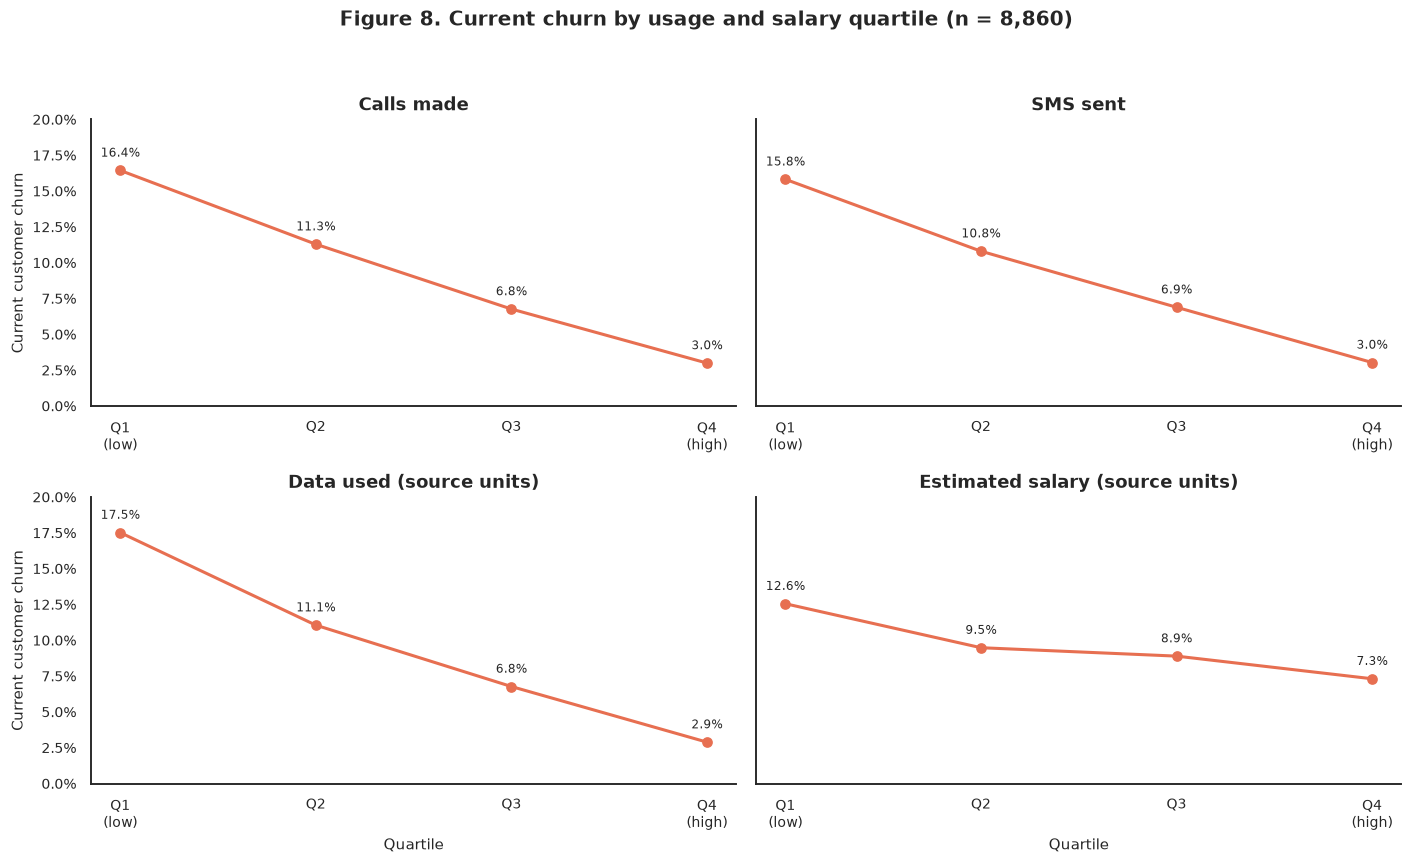

In [19]:
quartile_labels = ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)

for ax, column in zip(axes.flat, usage_columns, strict=False):
    rates = (
        current_usage.groupby(f"{column}_quartile", observed=True)["churn"].mean() * 100
    ).reindex(quartile_labels)
    x = np.arange(len(quartile_labels))
    ax.plot(x, rates.values, marker="o", color=PALETTE["churned"], linewidth=2)
    for index, value in enumerate(rates.values):
        ax.annotate(
            f"{value:.1f}%",
            (index, value),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=8,
        )
    ax.set_xticks(x, ["Q1\n(low)", "Q2", "Q3", "Q4\n(high)"])
    ax.set_ylim(0, 20)
    ax.set_title(usage_labels[column])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    sns.despine(ax=ax)

for ax in axes[:, 0]:
    ax.set_ylabel("Current customer churn")
for ax in axes[-1, :]:
    ax.set_xlabel("Quartile")

fig.suptitle(
    "Figure 8. Current churn by usage and salary quartile (n = 8,860)",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

The usage gradient is strong and consistent:

- Calls: 16.4% in Q1 falls to 3.0% in Q4.
- SMS: 15.8% falls to 3.0%.
- Data: 17.5% falls to 2.9%.
- Salary: 12.6% falls to 7.3%, a much weaker gradient.

The first three metrics are correlated with each other. The next chart shows the full distribution by churn status rather than only the quartile means.

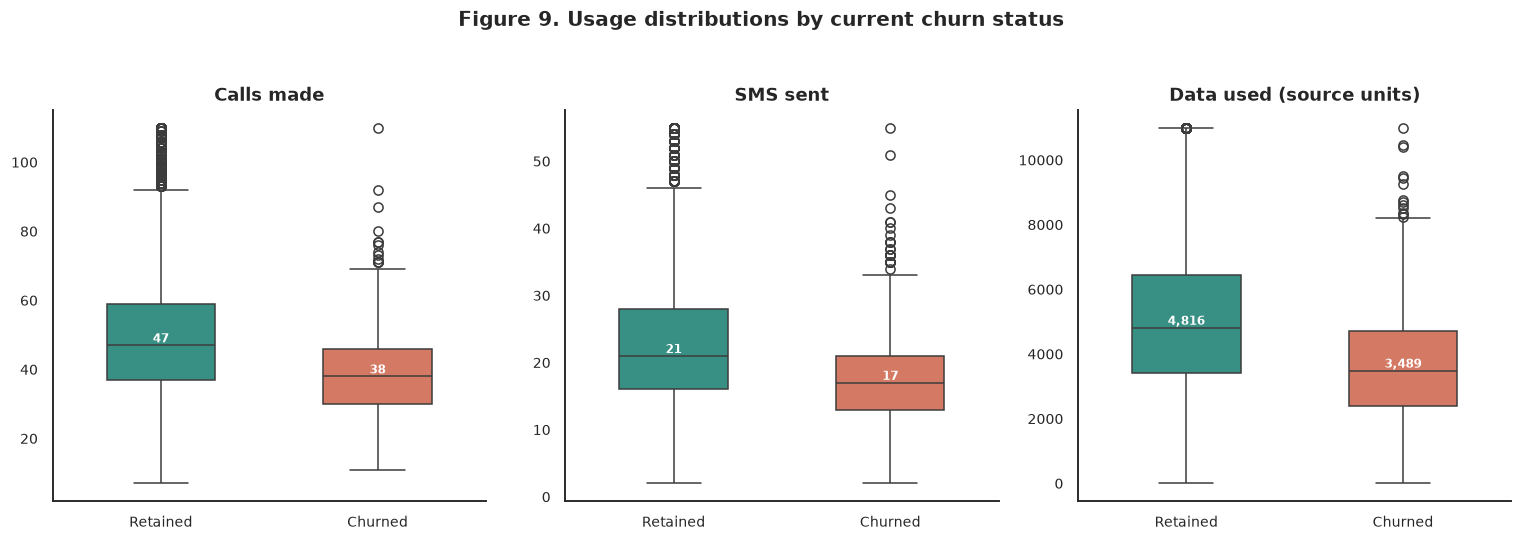

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, column in zip(axes, ["calls_made", "sms_sent", "data_used"], strict=False):
    sns.boxplot(
        data=current_status,
        x="status",
        y=column,
        hue="status",
        palette={"Retained": PALETTE["retained"], "Churned": PALETTE["churned"]},
        legend=False,
        width=0.5,
        ax=ax,
    )
    for index, status in enumerate(["Retained", "Churned"]):
        median = current_status.loc[current_status["status"] == status, column].median()
        ax.text(
            index,
            median,
            f"{median:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8,
            color="white",
            fontweight="bold",
        )
    ax.set_title(usage_labels[column])
    ax.set_xlabel("")
    ax.set_ylabel("")
    sns.despine(ax=ax)

fig.suptitle(
    "Figure 9. Usage distributions by current churn status",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [21]:
zero_data = current[current["data_used"] == 0]
zero_rate = 100 * zero_data["churn"].mean()
zero_low, zero_high = wilson_interval(int(zero_data["churn"].sum()), len(zero_data))
display(
    Markdown(
        f"**Zero-data note.** {len(zero_data)} current relationships report `data_used = 0`. "
        f"Their current churn rate is {zero_rate:.1f}% "
        f"(95% CI {100 * zero_low:.1f}%–{100 * zero_high:.1f}%). "
        "The sample is small, so the estimate is uncertain."
    )
)

**Zero-data note.** 40 current relationships report `data_used = 0`. Their current churn rate is 42.5% (95% CI 28.5%–57.8%). The sample is small, so the estimate is uncertain.

## 9. Correlation and associations

The heatmap uses Spearman rank correlation on current relationships. Spearman is robust to the mild skew in usage and does not assume a linear relationship.

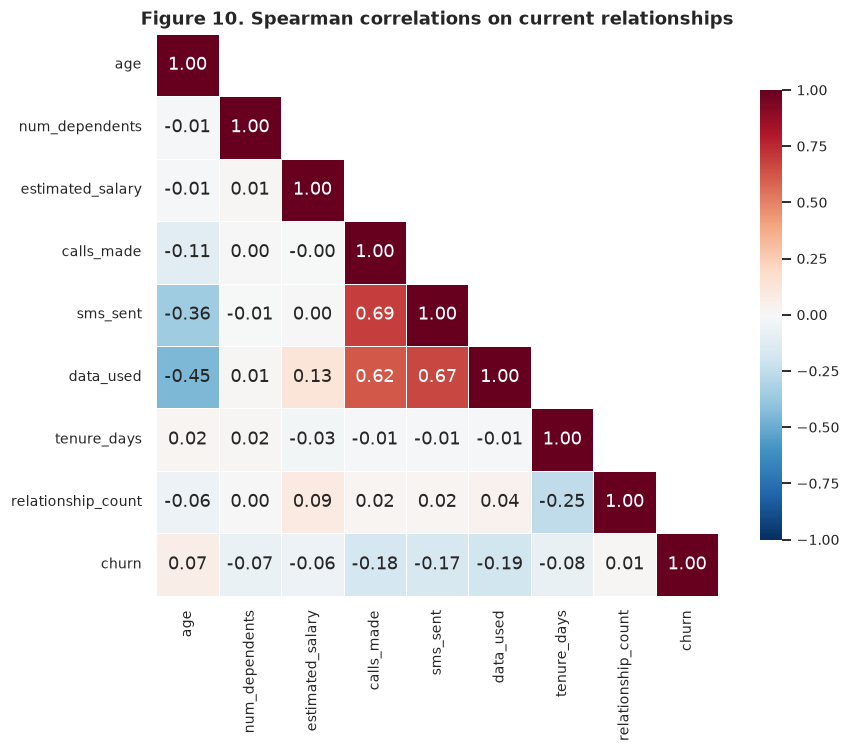

In [22]:
correlation_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_days",
    "relationship_count",
    "churn",
]
correlation = current[correlation_columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)
sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Figure 10. Spearman correlations on current relationships")
fig.tight_layout()
plt.show()

In [23]:
churn_correlation = (
    correlation["churn"].drop("churn").sort_values().to_frame("Spearman correlation")
)
display(churn_correlation.style.format("{:+.2f}"))

,Spearman correlation
data_used,-0.19
calls_made,-0.18
sms_sent,-0.17
tenure_days,-0.08
num_dependents,-0.07
estimated_salary,-0.06
relationship_count,+0.01
age,+0.07


The usage metrics correlate with each other at about 0.62–0.69. They also have the strongest negative rank correlation with churn:

- `data_used`: −0.19
- `calls_made`: −0.18
- `sms_sent`: −0.17
- `tenure_days`: −0.08
- `num_dependents`: −0.07
- `estimated_salary`: −0.06
- `relationship_count`: +0.01
- `age`: +0.07

Age also has negative rank correlation with SMS (−0.36) and data (−0.45). Older customers use less of both. A model must handle this overlap. These are associations, not causal effects.

`relationship_count` has almost no rank correlation with current churn, but it does correlate with tenure (−0.25). modeling work should test the model with and without it.

## 10. Temporal and cohort view

Registration dates span 2020-01-01 to 2023-05-04. The last quarter, 2023Q2, is partial. Current churn is a point-in-time status, not a cumulative cohort churn rate. Recent cohorts have shorter tenure at the snapshot, so their current churn is higher.

In [24]:
current["registration_year"] = current["registration_date"].dt.year
current["registration_quarter"] = current["registration_date"].dt.to_period("Q").astype(str)

year_table = current.groupby("registration_year").agg(
    n=("churn", "size"),
    churned=("churn", "sum"),
    median_tenure=("tenure_days", "median"),
)
year_table["current_churn_pct"] = 100 * year_table["churned"] / year_table["n"]
year_table["95% CI"] = [
    f"{100 * low:.2f}% – {100 * high:.2f}%"
    for low, high in [
        wilson_interval(int(churned), int(n))
        for churned, n in zip(year_table["churned"], year_table["n"], strict=False)
    ]
]
year_display = year_table.reset_index().rename(
    columns={
        "registration_year": "Registration year",
        "n": "Current relationships",
        "churned": "Current churn",
        "median_tenure": "Median tenure (days)",
        "current_churn_pct": "Current churn rate",
    }
)
display(
    year_display.style.hide(axis="index").format(
        {
            "Current relationships": "{:,}",
            "Current churn": "{:,}",
            "Median tenure (days)": "{:,.0f}",
            "Current churn rate": "{:.2f}%",
        }
    )
)

Registration year,Current relationships,Current churn,Median tenure (days),Current churn rate,95% CI
2020,"2,375",163,"1,031",6.86%,5.91% – 7.95%
2021,"2,486",222,667,8.93%,7.87% – 10.12%
2022,"2,929",328,305,11.20%,10.11% – 12.39%
2023,"1,070",134,59,12.52%,10.67% – 14.64%


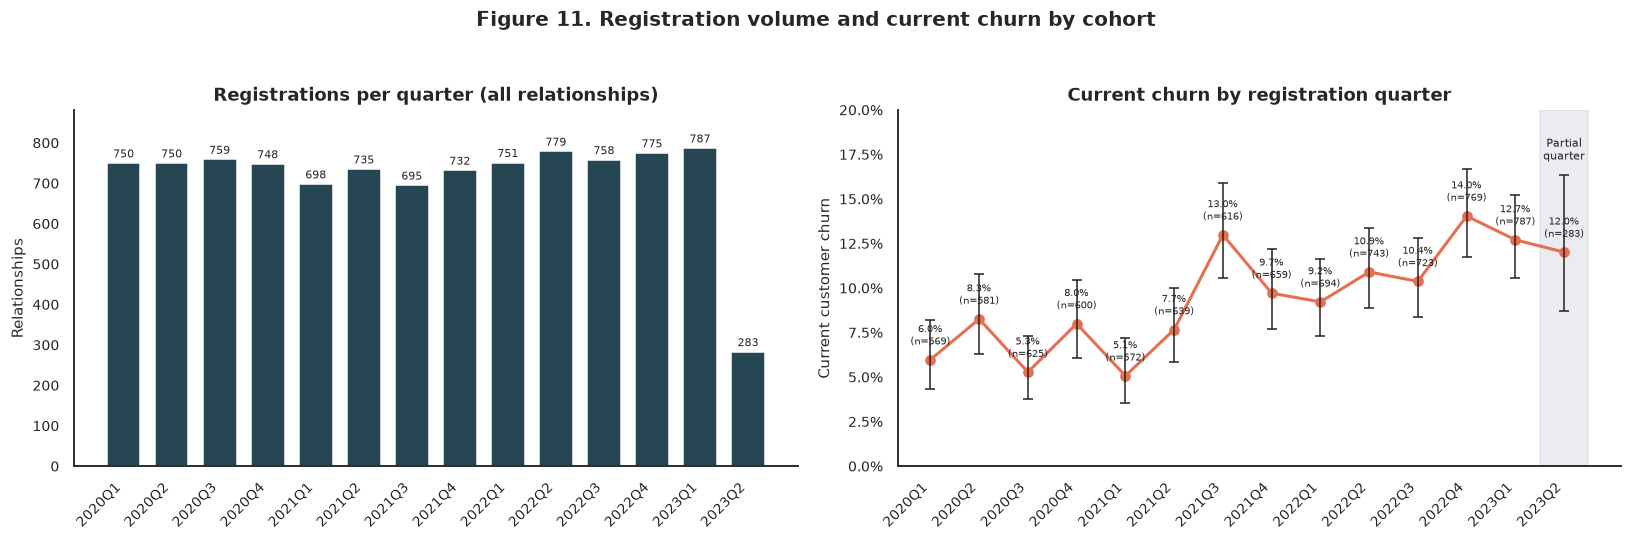

In [25]:
quarter_counts = history["registration_date"].dt.to_period("Q").value_counts().sort_index()
quarter_current = churn_summary(current, "registration_quarter")
quarter_current = quarter_current.sort_values("registration_quarter").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x_volume = np.arange(len(quarter_counts))
bars = axes[0].bar(x_volume, quarter_counts.values, color=PALETTE["current"], width=0.7)
axes[0].bar_label(
    bars, labels=[f"{value:,}" for value in quarter_counts.values], padding=2, fontsize=7
)
axes[0].set_xticks(
    x_volume, [str(quarter) for quarter in quarter_counts.index], rotation=45, ha="right"
)
axes[0].set_ylim(0, quarter_counts.max() * 1.12)
axes[0].set_ylabel("Relationships")
axes[0].yaxis.set_major_formatter(count_formatter)
axes[0].set_title("Registrations per quarter (all relationships)")
sns.despine(ax=axes[0])

x_churn = np.arange(len(quarter_current))
axes[1].plot(
    x_churn,
    quarter_current["rate_pct"],
    marker="o",
    color=PALETTE["churned"],
    linewidth=2,
)
axes[1].errorbar(
    x_churn,
    quarter_current["rate_pct"],
    yerr=[
        quarter_current["rate_pct"] - quarter_current["ci_low_pct"],
        quarter_current["ci_high_pct"] - quarter_current["rate_pct"],
    ],
    fmt="none",
    ecolor=PALETTE["ink"],
    capsize=3,
    linewidth=1,
)
for index, (rate, n) in enumerate(
    zip(quarter_current["rate_pct"], quarter_current["n"], strict=False)
):
    axes[1].annotate(
        f"{rate:.1f}%\n(n={n:,})",
        (index, rate),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=6.5,
    )
axes[1].set_xticks(
    x_churn,
    quarter_current["registration_quarter"],
    rotation=45,
    ha="right",
)
axes[1].set_ylim(0, 20)
axes[1].set_ylabel("Current customer churn")
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[1].set_title("Current churn by registration quarter")
last_index = len(quarter_current) - 1
axes[1].axvspan(last_index - 0.5, last_index + 0.5, color=PALETTE["history"], alpha=0.18)
axes[1].text(
    last_index,
    18.5,
    "Partial\nquarter",
    ha="center",
    va="top",
    fontsize=7,
    color=PALETTE["ink"],
)
sns.despine(ax=axes[1])

fig.suptitle(
    "Figure 11. Registration volume and current churn by cohort",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Current churn rises from 6.9% for the 2020 cohort to 12.5% for the 2023 cohort. The median tenure falls from 1,031 days to 59 days over the same period. This is consistent with the tenure gradient: newer customers have had less time to reach the lower-churn part of the tenure curve.

The quarterly line also shows that 2021Q3 and 2022Q4 are above their neighboring quarters. The sample sizes are 616 and 769. Do not treat quarter-to-quarter movement as a stable trend. A survival model would be needed to separate cohort, tenure, and calendar effects.

## 11. Segment interaction

Provider and usage are not independent. The heatmap crosses the four providers with calls-made quartiles. It shows whether the provider gap persists at every usage level.

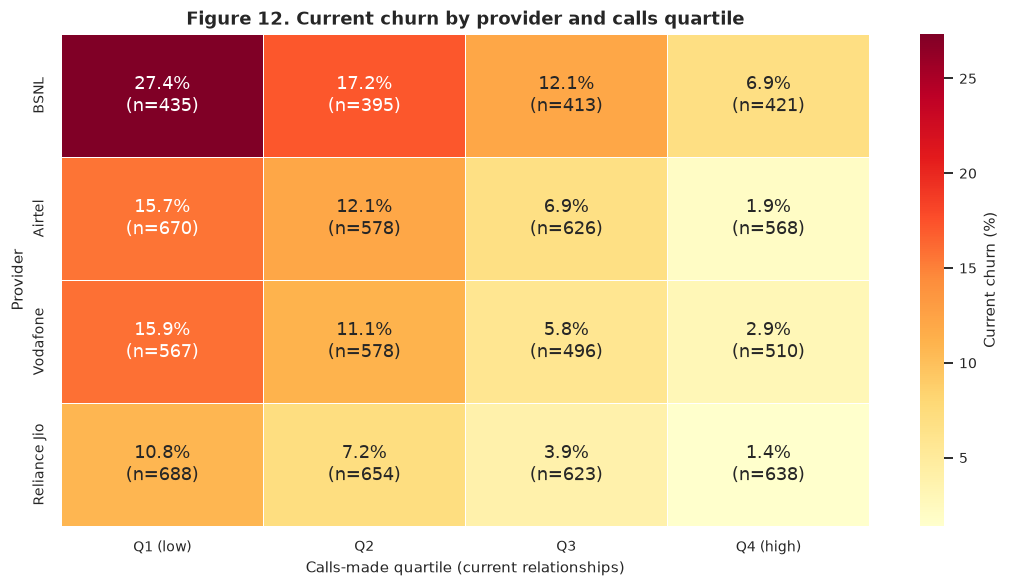

In [26]:
partner_order = partner["telecom_partner"].tolist()
quartile_order = ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]

interaction = (
    current_usage.pivot_table(
        index="telecom_partner",
        columns="calls_made_quartile",
        values="churn",
        aggfunc="mean",
        observed=True,
    )
    * 100
)
interaction = interaction.reindex(index=partner_order, columns=quartile_order)
interaction_counts = current_usage.pivot_table(
    index="telecom_partner",
    columns="calls_made_quartile",
    values="churn",
    aggfunc="size",
    observed=True,
).reindex(index=partner_order, columns=quartile_order)

annotations = np.empty(interaction.shape, dtype=object)
for row in range(interaction.shape[0]):
    for column in range(interaction.shape[1]):
        rate = interaction.iloc[row, column]
        n = interaction_counts.iloc[row, column]
        annotations[row, column] = f"{rate:.1f}%\n(n={n:,})"

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    interaction,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Current churn (%)"},
    ax=ax,
)
ax.set_xlabel("Calls-made quartile (current relationships)")
ax.set_ylabel("Provider")
ax.set_title("Figure 12. Current churn by provider and calls quartile")
fig.tight_layout()
plt.show()

The interaction is clear:

- BSNL is the highest-churn provider in every calls quartile. Its rate is 27.4% in Q1 and 6.9% in Q4.
- Reliance Jio is the lowest in every quartile. Its rate is 10.8% in Q1 and 1.4% in Q4.
- Every provider shows the same downward gradient as calls rise.

The provider gap is not just a usage mix. modeling work should test provider and usage jointly, with interaction terms or a tree-based model.

## 12. Key findings and modeling work handoff

The findings below are computed from the notebook variables so the numbers stay consistent with the charts.

In [27]:
calls_rates = (
    current_usage.groupby("calls_made_quartile", observed=True)["churn"].mean() * 100
).reindex(quartile_labels)
sms_rates = (
    current_usage.groupby("sms_sent_quartile", observed=True)["churn"].mean() * 100
).reindex(quartile_labels)
data_rates = (
    current_usage.groupby("data_used_quartile", observed=True)["churn"].mean() * 100
).reindex(quartile_labels)
salary_rates = (
    current_usage.groupby("estimated_salary_quartile", observed=True)["churn"].mean() * 100
).reindex(quartile_labels)

bsnl = partner_current.set_index("telecom_partner").loc["BSNL"]
jio = partner_current.set_index("telecom_partner").loc["Reliance Jio"]
highest_state = state_current.iloc[-1]
lowest_state = state_current.iloc[0]
tenure_low = tenure_current.set_index("tenure_band").loc["0–90"]
tenure_high = tenure_current.set_index("tenure_band").loc["731+"]
churned_tenure = current.loc[current["churn"], "tenure_days"].median()
retained_tenure = current.loc[~current["churn"], "tenure_days"].median()
gender_rates = gender_current.set_index("gender")["rate_pct"]

findings = [
    (
        f"**Grain.** The snapshot holds {report.row_count:,} customer-provider relationships "
        f"for {report.unique_customers:,} customers. {report.multi_relationship_customers:,} "
        f"customers have more than one provider relationship, and {report.reentry_pairs} "
        "customer-provider pairs recur later. These are valid history, not duplicates."
    ),
    (
        f"**Dual churn.** Relationship churn is {report.relationship_churn_rate:.2f}% "
        f"({report.relationship_churn_count:,} of {report.row_count:,}). Current customer churn "
        f"is {report.current_churn_rate:.2f}% ({report.current_churn_count:,} of "
        f"{report.current_relationships:,}). All {report.historical_relationships:,} historical "
        f"relationships are churned by construction. Never use {report.relationship_churn_rate:.2f}% "
        "as the current churn rate."
    ),
    (
        f"**Usage is the strongest descriptive signal.** Current churn falls from "
        f"{calls_rates.iloc[0]:.1f}% to {calls_rates.iloc[-1]:.1f}% across calls quartiles, "
        f"from {sms_rates.iloc[0]:.1f}% to {sms_rates.iloc[-1]:.1f}% across SMS quartiles, and "
        f"from {data_rates.iloc[0]:.1f}% to {data_rates.iloc[-1]:.1f}% across data quartiles."
    ),
    (
        f"**Tenure matters.** Current churn is {tenure_low['rate_pct']:.1f}% for 0–90 days "
        f"and {tenure_high['rate_pct']:.1f}% for 731+ days. Churned current relationships have "
        f"a median tenure of {churned_tenure:,.0f} days, compared with {retained_tenure:,.0f} "
        "days for retained relationships."
    ),
    (
        f"**Provider matters.** BSNL has the highest current churn at "
        f"{bsnl['current_rate_pct']:.1f}% ({int(bsnl['current_churned']):,} of "
        f"{int(bsnl['current_n']):,}). Reliance Jio has the lowest at "
        f"{jio['current_rate_pct']:.1f}% ({int(jio['current_churned']):,} of "
        f"{int(jio['current_n']):,}). BSNL stays highest across calls quartiles."
    ),
    (
        f"**Age and dependents associate with current churn.** Current churn rises from "
        f"{age_current_series.iloc[0]:.1f}% in the 18–24 band to "
        f"{age_current_series.iloc[-1]:.1f}% in the 65+ band. It falls from "
        f"{dependent_current_series.iloc[0]:.1f}% with no dependents to "
        f"{dependent_current_series.iloc[-1]:.1f}% with four. Gender shows no material "
        f"difference ({gender_rates.loc['F']:.2f}% F vs {gender_rates.loc['M']:.2f}% M)."
    ),
    (
        f"**Geography is weak and uncertain.** Among states with at least 100 current "
        f"relationships, {highest_state['state']} has the highest rate at "
        f"{highest_state['rate_pct']:.1f}% (n={int(highest_state['n']):,}). "
        f"{lowest_state['state']} has the lowest at {lowest_state['rate_pct']:.1f}% "
        f"(n={int(lowest_state['n']):,}). Pincode changes in every multi-provider group, so it "
        "is not a reliable geographic key."
    ),
    (
        f"**Recent cohorts show higher current churn.** The 2020 cohort has "
        f"{year_table.loc[2020, 'current_churn_pct']:.1f}% current churn and a median tenure of "
        f"{year_table.loc[2020, 'median_tenure']:,.0f} days. The 2023 cohort has "
        f"{year_table.loc[2023, 'current_churn_pct']:.1f}% and "
        f"{year_table.loc[2023, 'median_tenure']:,.0f} days. This is consistent with shorter "
        "tenure, not proof of a worsening trend. The 2023Q2 quarter is partial."
    ),
    (
        f"**Salary has a weak gradient.** Current churn falls from {salary_rates.iloc[0]:.1f}% "
        f"in the lowest salary quartile to {salary_rates.iloc[-1]:.1f}% in the highest. The "
        "effect is much weaker than the usage effect."
    ),
    (
        f"**modeling work must use the current grain only.** The modeling frame has "
        f"{len(current):,} rows and {int(current['churn'].sum()):,} positives "
        f"({100 * current['churn'].mean():.2f}% churn). Exclude identifiers and pincode. Evaluate "
        "with PR-AUC, recall, F1, and calibration, not accuracy alone."
    ),
]

display(Markdown("\n".join(f"{index}. {finding}" for index, finding in enumerate(findings, 1))))

1. **Grain.** The snapshot holds 10,000 customer-provider relationships for 8,860 customers. 1,020 customers have more than one provider relationship, and 33 customer-provider pairs recur later. These are valid history, not duplicates.
2. **Dual churn.** Relationship churn is 19.87% (1,987 of 10,000). Current customer churn is 9.56% (847 of 8,860). All 1,140 historical relationships are churned by construction. Never use 19.87% as the current churn rate.
3. **Usage is the strongest descriptive signal.** Current churn falls from 16.4% to 3.0% across calls quartiles, from 15.8% to 3.0% across SMS quartiles, and from 17.5% to 2.9% across data quartiles.
4. **Tenure matters.** Current churn is 12.1% for 0–90 days and 6.6% for 731+ days. Churned current relationships have a median tenure of 430 days, compared with 562 days for retained relationships.
5. **Provider matters.** BSNL has the highest current churn at 16.0% (266 of 1,664). Reliance Jio has the lowest at 5.9% (154 of 2,603). BSNL stays highest across calls quartiles.
6. **Age and dependents associate with current churn.** Current churn rises from 8.1% in the 18–24 band to 14.2% in the 65+ band. It falls from 12.2% with no dependents to 6.7% with four. Gender shows no material difference (9.51% F vs 9.59% M).
7. **Geography is weak and uncertain.** Among states with at least 100 current relationships, Uttarakhand has the highest rate at 13.4% (n=112). Haryana has the lowest at 7.1% (n=282). Pincode changes in every multi-provider group, so it is not a reliable geographic key.
8. **Recent cohorts show higher current churn.** The 2020 cohort has 6.9% current churn and a median tenure of 1,031 days. The 2023 cohort has 12.5% and 59 days. This is consistent with shorter tenure, not proof of a worsening trend. The 2023Q2 quarter is partial.
9. **Salary has a weak gradient.** Current churn falls from 12.6% in the lowest salary quartile to 7.3% in the highest. The effect is much weaker than the usage effect.
10. **modeling work must use the current grain only.** The modeling frame has 8,860 rows and 847 positives (9.56% churn). Exclude identifiers and pincode. Evaluate with PR-AUC, recall, F1, and calibration, not accuracy alone.

### modeling work feature contract

| Feature | Role | Reason |
|---|---|---|
| `telecom_partner` | Candidate | Four providers with different current churn rates |
| `gender` | Candidate | Stable customer attribute; weak univariate signal |
| `age` | Candidate | Current churn rises in older bands |
| `state` | Candidate, grouped | 32 levels; group rare states or encode within cross-validation |
| `num_dependents` | Candidate | Current churn falls as dependents rise |
| `estimated_salary` | Candidate | Weak negative association; relationship-level value |
| `calls_made` | Candidate | Strong negative association |
| `sms_sent` | Candidate | Strong negative association |
| `data_used` | Candidate | Strong negative association; unit undocumented |
| `tenure_days` | Candidate | Current tenure at the snapshot |
| `relationship_count` | Candidate with test | Almost no rank correlation with current churn; correlates with tenure |
| `customer_id` | Exclude | Identifier; would overfit |
| `pincode` | Exclude | Synthetic noise; changes in every multi-provider group |
| `city` | Exclude | 81 levels and small samples |
| `record_id`, `dataset_id` | Exclude | Identifiers |
| `source_row_number` | Exclude | Ingestion metadata |
| `is_latest_relationship` | Exclude | Constant on the current grain |
| `relationship_seq` | Exclude | Equals relationship count on the current grain |
| `date_of_registration` | Exclude | Use `tenure_days` instead |
| `created_at` | Exclude | Ingestion timestamp |

The candidate features are known at the snapshot date. Do not use the target `churn` as a feature. Do not use historical rows.

In [28]:
candidate_features = [
    "telecom_partner",
    "gender",
    "age",
    "state",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_days",
    "relationship_count",
]
excluded_features = [
    "customer_id",
    "pincode",
    "city",
    "record_id",
    "dataset_id",
    "source_row_number",
    "is_latest_relationship",
    "relationship_seq",
    "date_of_registration",
    "created_at",
]

model_frame = current.copy()

assert len(model_frame) == 8_860
assert int(model_frame["churn"].sum()) == 847
assert round(100 * model_frame["churn"].mean(), 2) == 9.56
assert model_frame["customer_id"].is_unique
assert model_frame["is_latest_relationship"].all()
assert set(candidate_features).issubset(model_frame.columns)
assert not set(candidate_features) & set(excluded_features)
assert "churn" not in candidate_features

display(model_frame[[*candidate_features, "churn"]].head(5))

,telecom_partner,gender,age,state,num_dependents,estimated_salary,calls_made,sms_sent,data_used,tenure_days,relationship_count,churn
0,Reliance Jio,F,43,Kerala,2,65601,39,18,3741,1141,1,False
2,Vodafone,M,36,Tamil Nadu,1,142193,51,25,5336,190,2,False
4,BSNL,M,64,Bihar,2,130634,53,18,3063,418,2,True
5,Airtel,F,69,Uttar Pradesh,3,92316,66,20,4805,488,1,False
6,Vodafone,F,35,Meghalaya,0,119727,37,19,2653,404,1,False


### Modeling recommendations for modeling work

- Use `current` only. The 8,860 latest relationships are one row per customer.
- Build a stratified train/test split. Keep the positive rate near 9.56% in both parts.
- Start with a logistic regression baseline. Compare it with a tree-based model.
- Use PR-AUC as the primary ranking metric. Also report ROC-AUC, recall, F1, and calibration.
- Do not use accuracy alone. A model that predicts “retained” for every row scores about 90.4%.
- Handle class imbalance in the model or the decision threshold. Do not resample before the split.
- Fit all encoding and scaling inside cross-validation. Group rare states before encoding.
- Check the model with and without `relationship_count`.
- Run a time-aware robustness check. Train on older cohorts and test on newer cohorts. Report the difference from the random split.
- Do not use pincode, customer ID, or any identifier.
- Do not use historical rows. Their churn is determined by the construction rule.

## 13. Limitations and appendix

### Limitations

- The snapshot is synthetic. The findings describe this file, not the telecom market.
- The dataset has no churn date. Tenure uses the next registration date or the snapshot date as a proxy.
- Latest relationships are right-censored at 2023-05-04. A customer who would churn later is counted as retained.
- All 1,140 historical relationships are churned by construction. Their rate is not a behavioral estimate.
- Pincode changes in every multi-provider group and is not a reliable geographic key. Salary also changes in every group.
- State and city change in a minority of groups. Treat them as relationship-level context.
- Several states and segments have small samples. The confidence intervals show that uncertainty.
- The analysis is descriptive. It does not identify causal effects.
- No model is trained in this notebook. modeling work owns model selection, validation, and evaluation.

In [29]:
validation_report = pd.DataFrame(
    {
        "Field": [
            "Rows",
            "Source columns",
            "Unique customers",
            "Multi-provider customers",
            "Relationship count distribution",
            "Re-entry pairs",
            "Snapshot date",
            "First registration",
            "Last registration",
            "Relationship churn",
            "Historical relationships",
            "Historical churned",
            "Current relationships",
            "Current churned",
            "Errors",
            "Warnings",
        ],
        "Value": [
            f"{report.row_count:,}",
            f"{report.column_count}",
            f"{report.unique_customers:,}",
            f"{report.multi_relationship_customers:,}",
            str(report.relationship_count_distribution),
            f"{report.reentry_pairs}",
            f"{report.as_of_date:%Y-%m-%d}",
            f"{report.date_min:%Y-%m-%d}",
            f"{report.date_max:%Y-%m-%d}",
            f"{report.relationship_churn_count:,} ({report.relationship_churn_rate:.2f}%)",
            f"{report.historical_relationships:,}",
            f"{report.historical_churned:,}",
            f"{report.current_relationships:,}",
            f"{report.current_churn_count:,} ({report.current_churn_rate:.2f}%)",
            f"{report.error_count}",
            f"{report.warning_count}",
        ],
    }
)
display(validation_report.style.hide(axis="index"))

Field,Value
Rows,"10,000"
Source columns,14
Unique customers,"8,860"
Multi-provider customers,"1,020"
Relationship count distribution,"{'1': 7840, '2': 900, '3': 120}"
Re-entry pairs,33
Snapshot date,2023-05-04
First registration,2020-01-01
Last registration,2023-05-04
Relationship churn,"1,987 (19.87%)"


In [30]:
environment = pd.DataFrame(
    {
        "Component": ["Python", "pandas", "NumPy", "matplotlib", "seaborn"],
        "Version": [
            sys.version.split()[0],
            pd.__version__,
            np.__version__,
            matplotlib.__version__,
            sns.__version__,
        ],
    }
)
display(environment.style.hide(axis="index"))
display(Markdown(f"**Dataset SHA-256:** `{file_sha256}`"))

Component,Version
Python,3.13.18
pandas,3.1.1
NumPy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2


**Dataset SHA-256:** `a1c3992fcb8da9523aa0f8074f87ce0c2247cac551e3a4fdee02c2690aa2f048`

### Data dictionary

| Column | Type | Meaning |
|---|---|---|
| `customer_id` | text | Customer identifier; repeats across provider relationships |
| `telecom_partner` | text | Provider: Airtel, BSNL, Reliance Jio, or Vodafone |
| `gender` | text | `M` or `F` |
| `age` | integer | Customer age at the relationship |
| `state` | text | State or union territory |
| `city` | text | City |
| `pincode` | text | Six-digit pincode; synthetic and unstable across relationships |
| `date_of_registration` | date | Provider registration date |
| `num_dependents` | integer | Number of dependents |
| `estimated_salary` | integer | Estimated salary in source units |
| `calls_made` | integer | Calls made in the relationship period |
| `sms_sent` | integer | SMS sent in the relationship period |
| `data_used` | integer | Data used in source units |
| `churn` | boolean | Provider-specific churn flag |
| `source_row_number` | integer | 1-based source data row |
| `relationship_seq` | integer | 1-based order by registration date and source row |
| `relationship_count` | integer | Number of provider relationships for the customer |
| `is_latest_relationship` | boolean | True only for the customer's latest relationship |
| `tenure_days` | integer | Historical: next registration minus current. Latest: snapshot minus current |

See `Dataset/README.md` for the full data contract.

### Reproducibility

```bash
uv sync --group notebook
uv run --group notebook jupyter nbconvert   --to notebook --execute --inplace   --ExecutePreprocessor.timeout=900   Python/analysis.ipynb
```

The notebook reads `Dataset/project_dataset.csv` and does not connect to Neon. The committed file hash matches the data validation canonical dataset.

**End of analysis notebook exploratory data analysis.**